# Bandpass filter (IIR)- Bilinear transform
# Analog-to-digital filter conversion via bilinear transform with documented pre-warping calculations (in code) 

In [25]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import scipy.signal as signal

def prewarp_frequency(f, fs):
    """
    Pre-warp the digital frequency f and convert it to angular frequency w (rad/s).
    Returns pre-warped angular frequency (wc) in rad/s.
    """
    if fs <= 0:
        raise ValueError("Sampling frequency must be positive.")
    if not (0 < f < fs / 2):
        raise ValueError("Frequency must be between 0 and Nyquist frequency.")

    Ts = 1.0 / fs  # Sampling period
    w = 2 * np.pi * f  # Digital angular frequency in rad/s

    # Pre-warping 
    pre_warped_w = 2/Ts * np.tan(w * Ts / 2)

    return pre_warped_w



#### First design an analog lowpass Butterworth filter.
#### Then convert it to a bandpass filter using the lowpass-to-bandpass transformation with pre-warping.
#### Finally convert it to a digital filter using the bilinear transform.

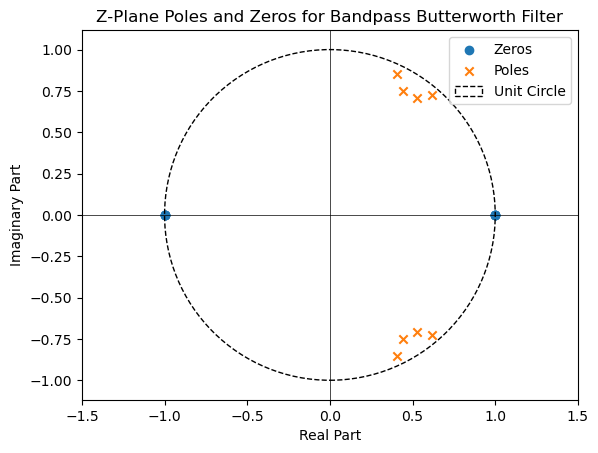

In [ ]:
passband_1 = 6e3
passband_2 = 8e3

fs = 44100  # sampling frequency

order = 4  # filter order

b, a = signal.iirfilter(Wn=1.0, N=order, analog=True, ftype='butter', btype='low')  # Design an analog lowpass Butterworth filter with cutoff frequency of 1 rad/s

#print(f"Numerator Coefficients lowpass filter: {b}")
#print(f"Denominator Coefficients lowpass filter: {a}")

omega_passband1 = prewarp_frequency(passband_1, fs)
omega_passband2 = prewarp_frequency(passband_2, fs)

omega_passband_center = np.sqrt(omega_passband1 * omega_passband2) # we use the geometric mean to find the center frequency of the passband, alternative calcutlate f_center and then prearp
omega_passband_width = omega_passband2 - omega_passband1
#print(f"center angular frequency: {omega_passband_center:.2f} and width: {omega_passband_width:.2f} rad/s")

# We apply the prewarping to the passband frequencies before converting the lowpass filter to a bandpass filter. 
b,a = signal.lp2bp(b, a, omega_passband_center, omega_passband_width)  # convert to bandpass filter 
# note the order of the filter is doubled when converting from lowpass to bandpass, so we have an 8th order bandpass filter.
#print("Numerator Coefficients bandpass filter:", b)
#print("Denominator Coefficients bandpass filter:", a)

b,a = signal.bilinear(b, a, fs=fs)
#print("Numerator Coefficients after bilinear transform:", b)
#print("Denominator Coefficients after bilinear transform:", a)

z, p, k = signal.tf2zpk(b, a)
#for i in range(len(z)): # 4 zeros at -1 and 4 at 1
#    print(f"Zero {i+1}: {z[i]}")
#for i in range(len(p)): # 4 complex conjugate pairs of poles
#    print(f"Poles {i+1}: {p[i]}")

# plot poles and zeros
plt.figure()
plt.scatter(np.real(z), np.imag(z), marker='o', label='Zeros')
plt.scatter(np.real(p), np.imag(p), marker='x', label='Poles')
unit_circle = patches.Circle((0, 0), 1, color='black', fill=False, linestyle='--', label='Unit Circle')
plt.gca().add_patch(unit_circle)
plt.title('Z-Plane Poles and Zeros for Bandpass Butterworth Filter')
plt.xlabel('Real Part')
plt.ylabel('Imaginary Part')
plt.axis('equal')
plt.xlim([-1.5, 1.5])
plt.ylim([-1.5, 1.5])

plt.axhline(0, color='black', lw=0.5)
plt.axvline(0, color='black', lw=0.5)

plt.legend()
plt.show()

C:\Users\asger\AppData\Local\Temp\ipykernel_21656\1849165638.py:6: RuntimeWarning: divide by zero encountered in log10
  A = 20 * np.log10(abs(h))


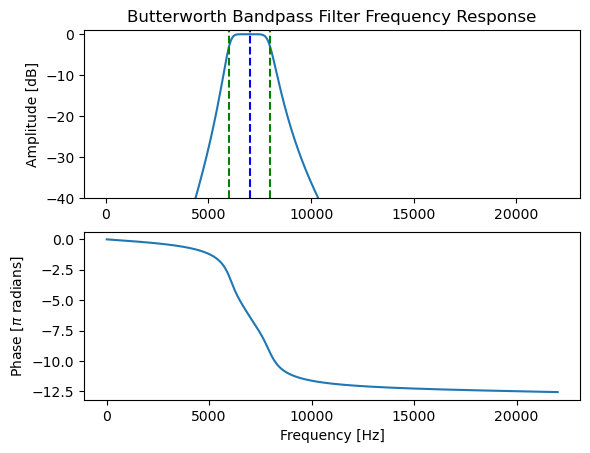

In [29]:

# evualute the frequency response of the filter
w, h = signal.freqz(b, a, fs=fs)

# bode plot
plt.figure()
A = 20 * np.log10(abs(h))
plt.subplot(2, 1, 1)
plt.plot(w, A)
plt.title('Butterworth Bandpass Filter Frequency Response')
plt.ylabel('Amplitude [dB]')
plt.ylim(-40, 1)
passband_center = (passband_1 + passband_2) / 2
plt.axvline(passband_center, color='blue', linestyle='--') # vertical line at the center of the passband
plt.axvline(passband_1, color='green', linestyle='--') # vertical line at 6 kHz
plt.axvline(passband_2, color='green', linestyle='--') # vertical line at 8 kHz

plt.subplot(2, 1, 2)
plt.plot(w, np.unwrap(np.angle(h)))

plt.xlabel('Frequency [Hz]')
plt.ylabel('Phase [$\pi$ radians]')
plt.show() 

## Test against creating a digital bandpass filter with signal.iirfilter

C:\Users\asger\AppData\Local\Temp\ipykernel_21656\1183352659.py:10: RuntimeWarning: divide by zero encountered in log10
  A = 20 * np.log10(abs(h))


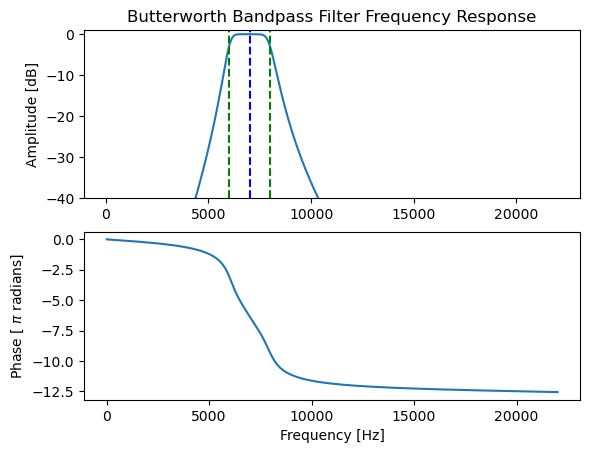

In [28]:
# directly design a digital bandpass filter using the iirfilter function 
b, a = signal.iirfilter(Wn=[passband_1, passband_2], N=order, analog=False, ftype='butter', btype='bandpass', fs=fs, output='ba') 


# evualute the frequency response of the filter
w, h = signal.freqz(b, a, fs=fs)

# bode plot
plt.figure()
A = 20 * np.log10(abs(h))
plt.subplot(2, 1, 1)
plt.plot(w, A)
plt.title('Butterworth Bandpass Filter Frequency Response')
plt.ylabel('Amplitude [dB]')
plt.ylim(-40, 1)
passband_center = (passband_1 + passband_2) / 2
plt.axvline(passband_center, color='blue', linestyle='--') # vertical line at the center of the passband
plt.axvline(passband_1, color='green', linestyle='--') # vertical line at 6 kHz
plt.axvline(passband_2, color='green', linestyle='--') # vertical line at 8 kHz

plt.subplot(2, 1, 2)
plt.plot(w, np.unwrap(np.angle(h)))

plt.xlabel('Frequency [Hz]')
plt.ylabel(f'Phase [ $\pi$ radians]')
plt.show() 